# Part 5 — Water Potability Scenario & Impact Analysis

**Student:** Joel Elizee  
**Student ID:** joeeli7267  
**Dataset:** `water_potability.csv` (3,276 samples; target `Potability`)  
**Model:** Part 4's optimized Random Forest classifier, refitted using the **same** random-search procedure and split.

> This project uses an optimized *traditional machine-learning model*, not a neural network. The assignment's allowance for other ML techniques from Part 3 is followed. Scenario effects are **model associations, not causal predictions or drinking-water safety advice**. All comparisons use the **held-out test subset** with consistent observations.

## 1. Recreate Part 4 classification model and evaluation

Reapply the Part 4 80/20 stratified split (random state 42), training-fold median imputation, and 6-iteration `RandomizedSearchCV` tuned for positive-class F1. The test set is *not* used in selection. Use predicted probabilities as the main scenario quantity because a hard 0.5 threshold can obscure smaller changes.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, log_loss
from IPython.display import display

SEED = 42
DATA = Path('water_potability.csv')
assert DATA.exists(), 'Place water_potability.csv beside this notebook.'
df = pd.read_csv(DATA)
features = df.drop(columns='Potability').columns.tolist()
itr, ite = train_test_split(df.index, test_size=.20, random_state=SEED, stratify=df.Potability)
train_df, test_df = df.loc[itr].copy(), df.loc[ite].copy()
X_train, X_test = train_df[features], test_df[features]
y_train, y_test = train_df.Potability, test_df.Potability
pipeline = Pipeline([('imputer', SimpleImputer(strategy='median')),
 ('forest', RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=1))])
search = RandomizedSearchCV(pipeline, param_distributions={
 'forest__n_estimators':[40,80], 'forest__max_depth':[4,6,8,12],
 'forest__min_samples_leaf':[3,6,10], 'forest__max_features':['sqrt',0.7]},
 n_iter=6, scoring='f1', cv=StratifiedKFold(3, shuffle=True, random_state=42),
 n_jobs=1, random_state=42, refit=True)
search.fit(X_train, y_train)
model = search.best_estimator_
proba = model.predict_proba(X_test)[:,1]
pred = (proba >= 0.5).astype(int)
metrics = {'accuracy': accuracy_score(y_test,pred), 'precision':precision_score(y_test,pred,zero_division=0),
 'recall':recall_score(y_test,pred,zero_division=0), 'f1':f1_score(y_test,pred,zero_division=0),
 'log_loss':log_loss(y_test,proba)}
print('Best hyperparameters:',search.best_params_)
print('Held-out test metrics:',{k:round(v,4) for k,v in metrics.items()})
print('Confusion matrix:',confusion_matrix(y_test,pred).tolist())
print('Held-out sample size:',len(X_test))

Best hyperparameters: {'forest__n_estimators': 40, 'forest__min_samples_leaf': 10, 'forest__max_features': 'sqrt', 'forest__max_depth': 12}
Held-out test metrics: {'accuracy': 0.6372, 'precision': 0.5446, 'recall': 0.4297, 'f1': 0.4803, 'log_loss': 0.6376}
Confusion matrix: [[308, 92], [146, 110]]
Held-out sample size: 656


## 2. Three distinct scenarios and assumptions

The changes below are *hypothetical stress tests*, not verified real-world treatment effects. Each scenario changes specified features **within the same 656 held-out samples** to isolate model response. Unmodified measurements and missing-value patterns are held constant, and the trained model is never refitted using simulated records.

1. **pH moderation (operational adjustment):** Move available pH readings 40% of the way toward pH 7: `7 + 0.6 × (pH − 7)`. This tests whether predictions react to measurements closer to neutral pH; it does **not** claim that treatment alone achieves this change.
2. **Runoff / sediment stress:** Increase `Solids` by 20% and `Turbidity` by 15%. These are plausible directional stress assumptions for degraded source-water conditions; the combination is illustrative rather than an observed event.
3. **Reduced disinfectant-related measures:** Reduce `Chloramines` and `Trihalomethanes` by 20% each. This probes response to simultaneous decreases, but **must not** be interpreted as advice to lower disinfectant concentrations—insufficient disinfection can be unsafe.

**Important cautions:** Some synthetic feature combinations might not occur naturally; potability is a binary label, not a regulatory determination; predicted probabilities are uncalibrated and may be unreliable. Changes in model output do not prove that the simulated changes caused water quality to improve or deteriorate.

In [2]:
def make_scenario(x, name):
    s = x.copy(deep=True)
    if name == 'pH moderation':
        s['ph'] = 7 + 0.60*(s['ph']-7)
    elif name == 'Runoff stress':
        s['Solids'] = s['Solids']*1.20
        s['Turbidity'] = s['Turbidity']*1.15
    elif name == 'Lower disinfectant measures':
        s['Chloramines'] = s['Chloramines']*0.80
        s['Trihalomethanes'] = s['Trihalomethanes']*0.80
    else:
        raise ValueError(name)
    return s

baseline = model.predict_proba(X_test)[:,1]
scenario_names = ['pH moderation','Runoff stress','Lower disinfectant measures']
scenario_prob = {name:model.predict_proba(make_scenario(X_test,name))[:,1] for name in scenario_names}
rows = [{'Scenario':'Baseline', 'Mean predicted P(potable)':baseline.mean(),
         'Mean change (percentage points)':0.,'Predicted potable count':int((baseline>=.5).sum()),
         'Changed class vs baseline':0}]
for name, prob in scenario_prob.items():
    rows.append({'Scenario':name, 'Mean predicted P(potable)':prob.mean(),
      'Mean change (percentage points)':100*(prob-baseline).mean(),
      'Predicted potable count':int((prob>=.5).sum()),
      'Changed class vs baseline':int(np.sum((prob>=.5)!=(baseline>=.5)))})
results=pd.DataFrame(rows)
display(results.round(3))
print('Note: mean probability is NOT measured potability prevalence; these are conditional model scores.')

,Scenario,Mean predicted P(potable),Mean change (percentage points),Predicted potable count,Changed class vs baseline
0,Baseline,0.463,0.000,202,0
1,pH moderation,0.476,1.368,216,34
2,Runoff stress,0.465,0.280,213,63
3,Lower disinfectant measures,0.464,0.181,196,68


Note: mean probability is NOT measured potability prevalence; these are conditional model scores.


### Reading the scenario outputs

Compare each row to **Baseline** (identical samples and fitted model). The average shift measures model sensitivity to a scenario. A predicted class flip only occurs when the output crosses the 0.5 threshold. No scenario is validated against actual treated or contaminated water samples.

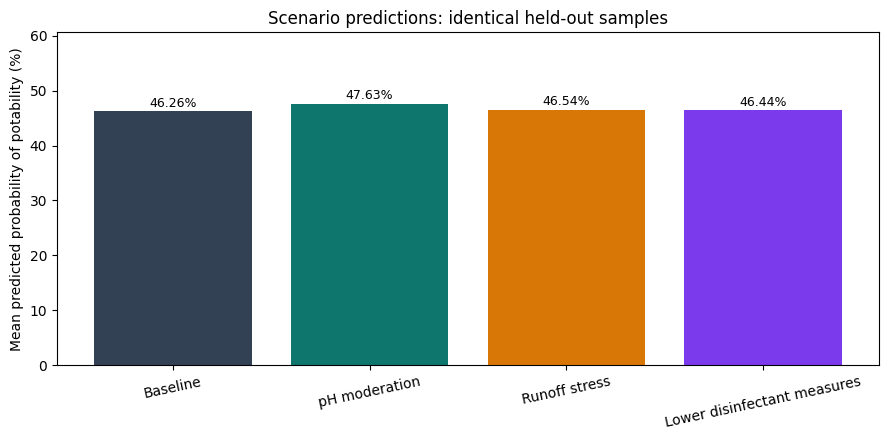

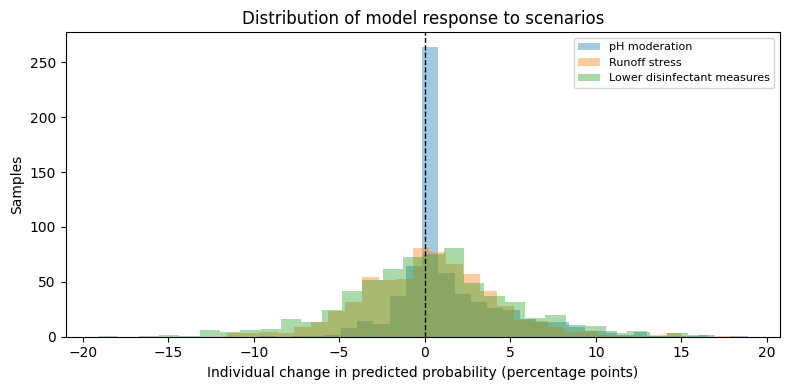

In [3]:
fig, ax=plt.subplots(figsize=(9,4.5))
labels=results['Scenario'].tolist()
vals=results['Mean predicted P(potable)'].to_numpy()*100
bars=ax.bar(labels,vals,color=['#334155','#0f766e','#d97706','#7c3aed'])
ax.set(ylabel='Mean predicted probability of potability (%)',title='Scenario predictions: identical held-out samples')
ax.set_ylim(0,max(vals)+13)
ax.tick_params(axis='x',labelrotation=12)
for b,v in zip(bars,vals):ax.text(b.get_x()+b.get_width()/2,v+0.8,f'{v:.2f}%',ha='center',fontsize=9)
plt.tight_layout();plt.savefig('part5_scenario_comparison.png',dpi=170);plt.show()
fig,ax=plt.subplots(figsize=(8,4))
for name in scenario_names:
    changes=100*(scenario_prob[name]-baseline)
    ax.hist(changes,bins=30,alpha=.4,label=name)
ax.axvline(0,color='black',linestyle='--',lw=1)
ax.set(xlabel='Individual change in predicted probability (percentage points)',ylabel='Samples',title='Distribution of model response to scenarios')
ax.legend(fontsize=8);plt.tight_layout();plt.savefig('part5_change_distributions.png',dpi=170);plt.show()

## 3. Two-feature sensitivity analysis — Solids and Turbidity

Using the **runoff stress** scenario as the motivating case, vary `Solids` and `Turbidity` by 0.80×, 0.90×, 1.00×, 1.10×, and 1.20× around their original held-out measurements. Keep other features unchanged and calculate mean model-predicted potability at each grid point. The 1.00×/1.00× center is the original held-out baseline. The parameter sweep tests *joint association* only; a 20% change in one variable does not imply that the other will remain fixed in reality.

Rows: Solids multiplier; columns: Turbidity multiplier


,80%,90%,100%,110%,120%
80%,46.09,46.02,46.05,46.07,46.01
90%,46.12,46.12,46.11,46.14,46.11
100%,46.17,46.26,46.26,46.34,46.29
110%,46.17,46.28,46.31,46.37,46.36
120%,46.23,46.36,46.43,46.49,46.51


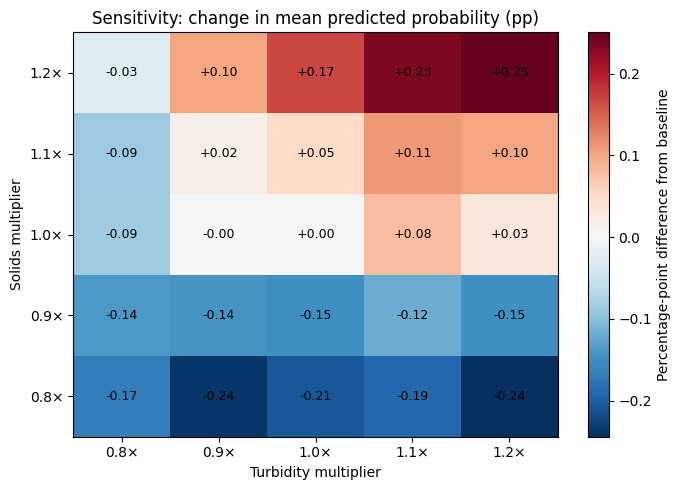

Grid minimum / maximum mean P(potable): 0.4601 0.4651
Corner (1.2× Solids, 1.2× Turbidity) vs baseline, pp: 0.251


In [4]:
from itertools import product
multipliers=np.array([.80,.90,1.,1.10,1.20])
grid=np.empty((len(multipliers),len(multipliers)))
for i,a in enumerate(multipliers):
    for j,b in enumerate(multipliers):
        s=X_test.copy()
        s['Solids']=s['Solids']*a
        s['Turbidity']=s['Turbidity']*b
        grid[i,j]=model.predict_proba(s)[:,1].mean()
sensitivity=pd.DataFrame(grid,index=[f'{int(z*100)}%' for z in multipliers],
 columns=[f'{int(z*100)}%' for z in multipliers])
print('Rows: Solids multiplier; columns: Turbidity multiplier')
display((sensitivity*100).round(2))
fig,ax=plt.subplots(figsize=(7,5))
im=ax.imshow(100*(grid-baseline.mean()),origin='lower',cmap='RdBu_r',aspect='auto')
ax.set_xticks(range(5),[f'{x:.1f}×' for x in multipliers]); ax.set_yticks(range(5),[f'{x:.1f}×' for x in multipliers])
ax.set(xlabel='Turbidity multiplier',ylabel='Solids multiplier',title='Sensitivity: change in mean predicted probability (pp)')
for i in range(5):
 for j in range(5):ax.text(j,i,f'{100*(grid[i,j]-baseline.mean()):+.2f}',ha='center',va='center',fontsize=9)
fig.colorbar(im,ax=ax,label='Percentage-point difference from baseline')
plt.tight_layout();plt.savefig('part5_sensitivity_heatmap.png',dpi=170);plt.show()
print('Grid minimum / maximum mean P(potable):',round(grid.min(),4),round(grid.max(),4))
print('Corner (1.2× Solids, 1.2× Turbidity) vs baseline, pp:',round(100*(grid[-1,-1]-baseline.mean()),3))

### Sensitivity interpretation and real-world implications

The heatmap describes how the **trained Random Forest changes its scores**, not how actual drinking-water safety changes. Flat sections are possible because tree models make piecewise-constant predictions. Effects can interact and need not be monotonic. These results may help **prioritize what to investigate or monitor**, but no specific chemical-treatment action should be taken without confirmatory sampling, validated laboratory tests, and applicable drinking-water standards. Running the same perturbations on an external dataset would provide a better robustness check.

## 4. Reflection on all three original analytical goals

- **Classification (potability):** Part 4 optimized Random Forest held-out accuracy was approximately **63.72%**, below Part 3's **66.16%**. Moderate performance and potential calibration concerns make this an educational screening exercise, **not** a drinkability decision tool.
- **Regression (pH):** Part 4 tuned Random Forest regressor had MAE around **1.2248 pH units** and R² near **0.013**. Its predictions barely explained held-out pH variation, suggesting these predictors are insufficient for reliable pH estimation.
- **Clustering (chemical patterns):** Optimized PCA + K-means selected **2 groups**, with test silhouette roughly **0.0823** (up from **0.0725**). Weak separation means these clusters should not be described as verified safety categories.

**Recommended next steps:** Collect more informative features and verify measurement quality, evaluate classification recall and probability calibration, review sample representativeness and potential leakage, validate scenarios with external observations, and have water-quality professionals evaluate results before any practical decisions. Models should **support**, not replace, laboratory testing.

## 5. Reproducibility and GitHub submission checklist

1. Put this notebook and `water_potability.csv` in one folder, install packages from `requirements.txt`, and run all cells in order. No external network or TensorFlow installation is required.
2. Upload the notebooks for Parts 2–5, data file (subject to course sharing rules), this README, and requirements to your GitHub repository.
3. Paste the **actual** new repository URL in your Word document; invite your instructor as a collaborator using their exact GitHub username from the course guide. No repository or invite was created by this notebook.
4. **Training/test note:** The scenarios are simulated on the existing held-out test subset and evaluated with an already trained model; they are not a new independent test dataset.